
# EV Energy Consumption Prediction - Milestone 3
## EDA, Business Insights, Feature Engineering, and Preprocessing

**Goal:** prepare the EV energy-consumption dataset for regression modeling.

**Important decisions**
- `Energy_Consumption_kWh` is the target variable.
- `Vehicle_ID` is an identifier, so it is not used as a predictive feature.
- `Timestamp` is used to order the data chronologically and create time features, then the raw timestamp is removed.
- The coded columns `Driving_Mode`, `Road_Type`, `Traffic_Condition`, and `Weather_Condition` are categorical, even though they are stored as integers.
- The data is split chronologically before fitting encoders or scalers to reduce leakage from future records into earlier records.
- We will inspect outliers, but will not automatically delete valid extreme observations without a domain reason.

# **Import libraries and load the dataset**

In [1]:
# Import pandas for data manipulation and NumPy for numerical operations.
import numpy as np
import pandas as pd

# Import Matplotlib and Seaborn for visual exploration.
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for preprocessing and a leak-safe machine-learning pipeline.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


In [22]:
df = pd.read_csv(r"C:\Users\njnay\Desktop\EVEnergyPrediction\Data\data.csv")
TARGET = "Energy_Consumption_kWh"

In [23]:
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset shape: 5,000 rows × 19 columns


,Vehicle_ID,Timestamp,Speed_kmh,Acceleration_ms2,Battery_State_%,Battery_Voltage_V,Battery_Temperature_C,Driving_Mode,Road_Type,Traffic_Condition,Slope_%,Weather_Condition,Temperature_C,Humidity_%,Wind_Speed_ms,Tire_Pressure_psi,Vehicle_Weight_kg,Distance_Travelled_km,Energy_Consumption_kWh
0,1102,2024-01-01 00:00:00,111.507366,-2.773816,30.415148,378.091525,25.314786,2,1,1,6.879446,4,0.741770,42.172533,7.829253,31.112020,1822.967368,20.757508,12.054317
1,1435,2024-01-01 00:01:00,48.612323,-0.796982,97.385534,392.718377,18.240755,1,2,1,-3.007212,4,-3.495516,57.018427,4.495572,31.504366,2091.831914,0.642918,4.488701
2,1860,2024-01-01 00:02:00,108.733320,0.253800,84.912600,398.993495,44.449145,1,1,3,0.029585,1,9.248275,69.028911,5.144489,33.838015,1816.702497,40.842824,11.701377
3,1270,2024-01-01 00:03:00,38.579484,-2.111395,28.777904,358.128273,28.980155,1,2,2,8.271943,3,2.868409,86.638349,4.518283,33.256014,1283.102642,5.305229,7.389266
4,1106,2024-01-01 00:04:00,57.172438,1.477883,29.740160,310.888162,33.184551,2,1,1,2.776814,2,16.750244,27.189185,4.263406,33.579678,2160.350788,5.825926,6.761205


In [25]:
print("\nData information:")
df.info()


Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Vehicle_ID              5000 non-null   int64  
 1   Timestamp               5000 non-null   object 
 2   Speed_kmh               5000 non-null   float64
 3   Acceleration_ms2        5000 non-null   float64
 4   Battery_State_%         5000 non-null   float64
 5   Battery_Voltage_V       5000 non-null   float64
 6   Battery_Temperature_C   5000 non-null   float64
 7   Driving_Mode            5000 non-null   int64  
 8   Road_Type               5000 non-null   int64  
 9   Traffic_Condition       5000 non-null   int64  
 10  Slope_%                 5000 non-null   float64
 11  Weather_Condition       5000 non-null   int64  
 12  Temperature_C           5000 non-null   float64
 13  Humidity_%              5000 non-null   float64
 14  Wind_Speed_ms        

In [15]:

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing_Count"))
print(f"Duplicate rows: {df.duplicated().sum():,}")


Missing values by column:


,Missing_Count
Vehicle_ID,0
Timestamp,0
Speed_kmh,0
Acceleration_ms2,0
Battery_State_%,0
Battery_Voltage_V,0
Battery_Temperature_C,0
Driving_Mode,0
Road_Type,0
Traffic_Condition,0


Duplicate rows: 0


In [16]:
# Show descriptive statistics for numeric columns.
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Vehicle_ID,5000.0,1505.701200,290.836902,1000.000000,1253.000000,1510.000000,1761.000000,1999.000000
Speed_kmh,5000.0,59.312952,34.517605,0.001396,29.515400,58.646794,89.030001,119.946924
Acceleration_ms2,5000.0,-0.019885,1.724287,-2.999683,-1.490240,-0.043329,1.473887,2.998039
Battery_State_%,5000.0,60.214465,23.128262,20.020196,40.088318,60.490283,80.409928,99.993986
Battery_Voltage_V,5000.0,351.118306,28.968372,300.004812,326.613439,351.510915,375.968140,399.990098
Battery_Temperature_C,5000.0,27.510130,10.015385,10.003858,18.884742,27.581710,35.920162,44.985943
Driving_Mode,5000.0,2.011000,0.810068,1.000000,1.000000,2.000000,3.000000,3.000000
Road_Type,5000.0,1.999200,0.808536,1.000000,1.000000,2.000000,3.000000,3.000000
Traffic_Condition,5000.0,2.010800,0.812167,1.000000,1.000000,2.000000,3.000000,3.000000
Slope_%,5000.0,2.504690,4.360854,-4.991079,-1.235653,2.452368,6.366990,9.998358


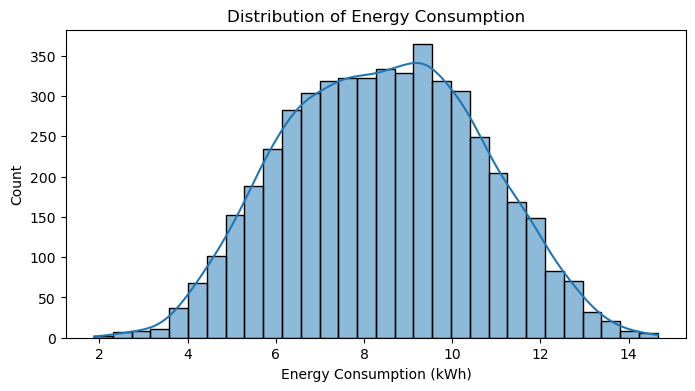

In [27]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x=TARGET, bins=30, kde=True)

plt.title("Distribution of Energy Consumption")
plt.xlabel("Energy Consumption (kWh)")
plt.show()

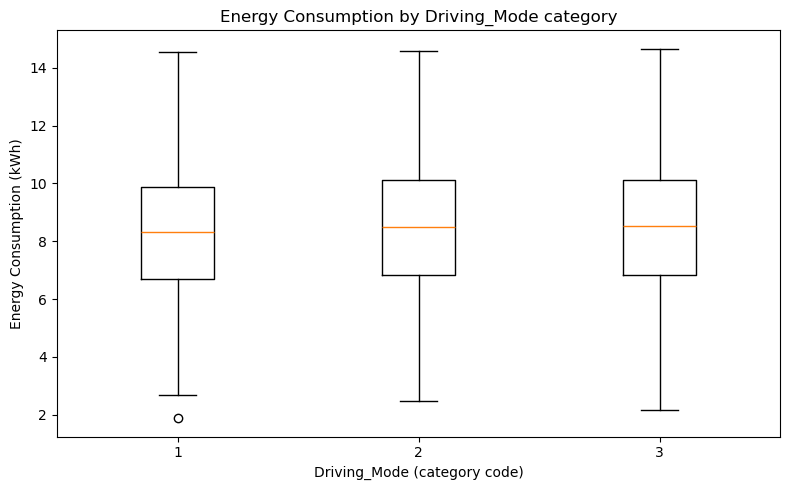

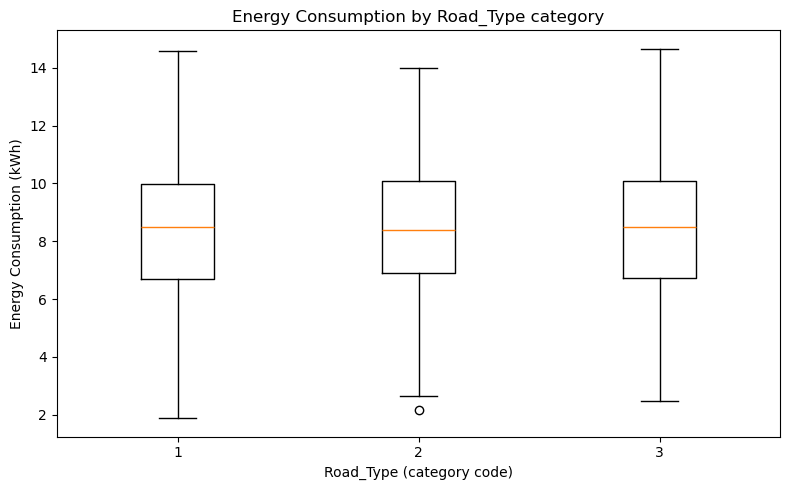

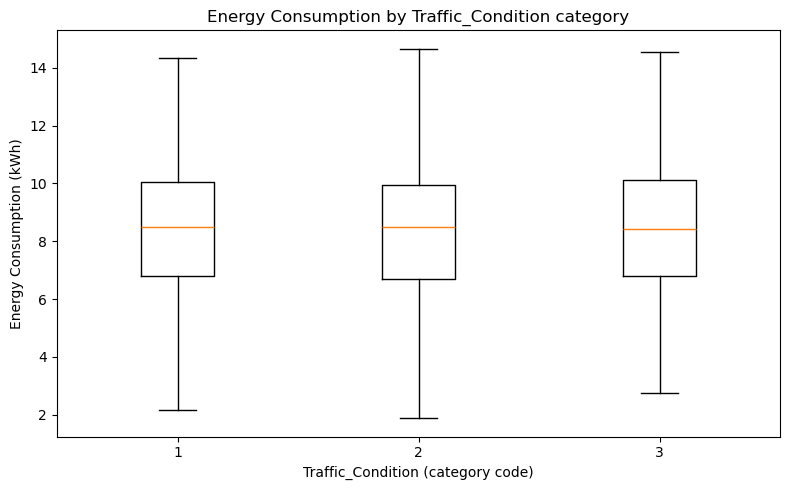

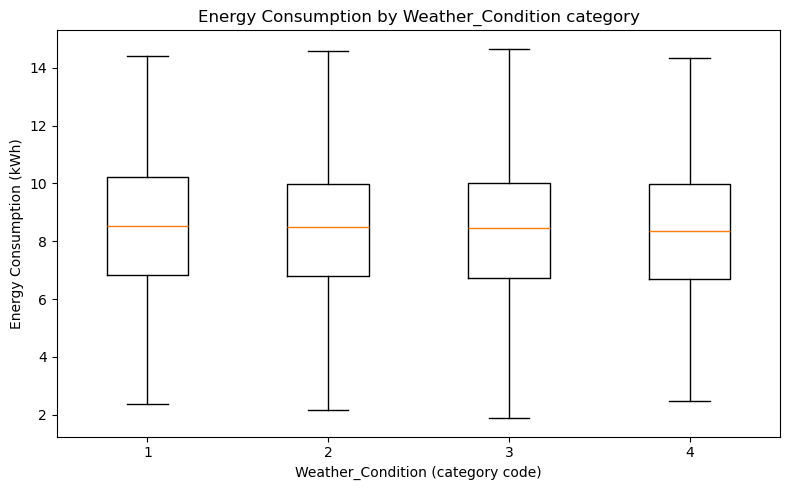

In [31]:
categorical_columns = [
    "Driving_Mode",
    "Road_Type",
    "Traffic_Condition",
    "Weather_Condition"
]

for column in categorical_columns:
    plt.figure(figsize=(8, 5))
    plt.boxplot([df.loc[df[column] == category, target].dropna() for category in sorted(df[column].dropna().unique())], tick_labels=sorted(df[column].dropna().unique()), patch_artist=False)
    plt.title(f"Energy Consumption by {column} category")
    plt.xlabel(f"{column} (category code)")
    plt.ylabel("Energy Consumption (kWh)")
    plt.tight_layout()
    plt.show()

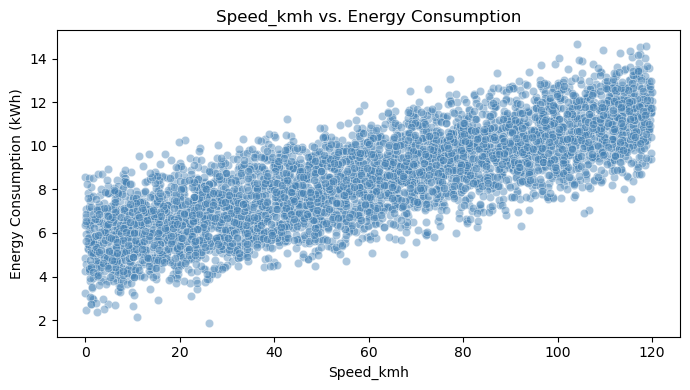

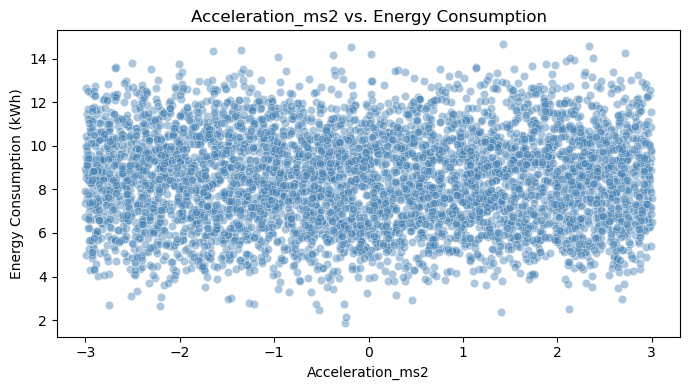

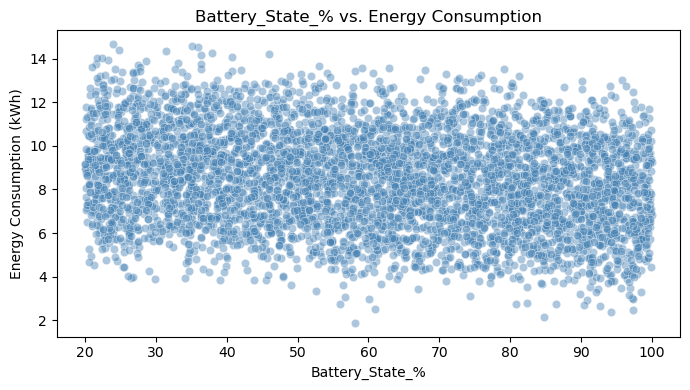

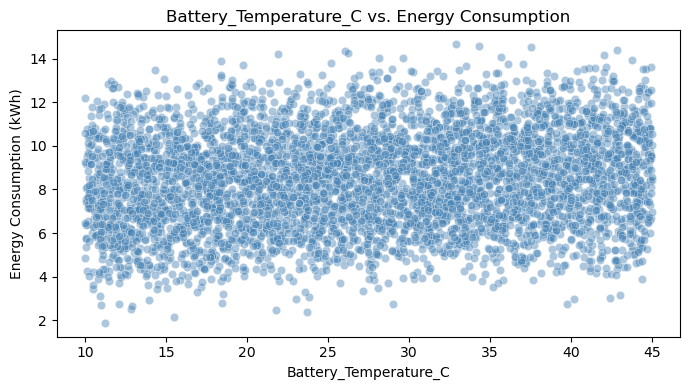

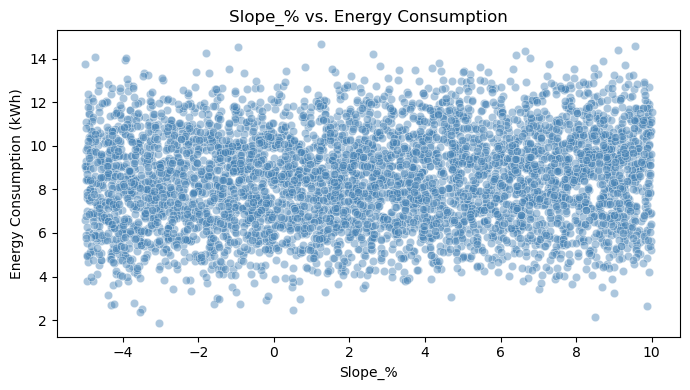

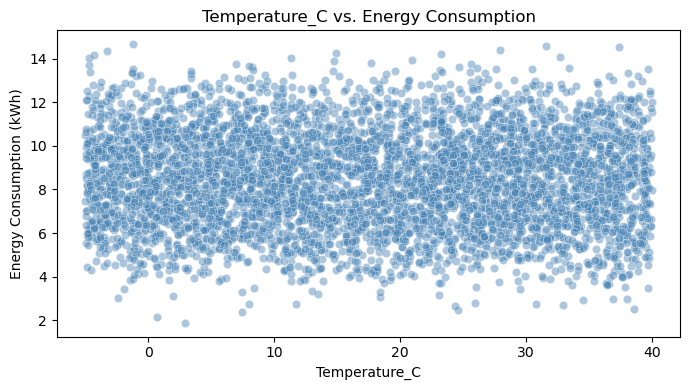

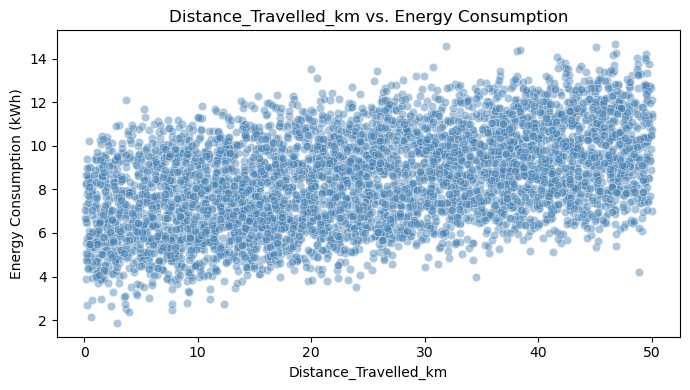

In [32]:
numeric_columns = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Distance_Travelled_km"
]

for column in numeric_columns:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x=column, y=target, alpha=0.45, color="steelblue")
    plt.title(f"{column} vs. Energy Consumption")
    plt.xlabel(column)
    plt.ylabel("Energy Consumption (kWh)")
    plt.tight_layout()
    plt.show()

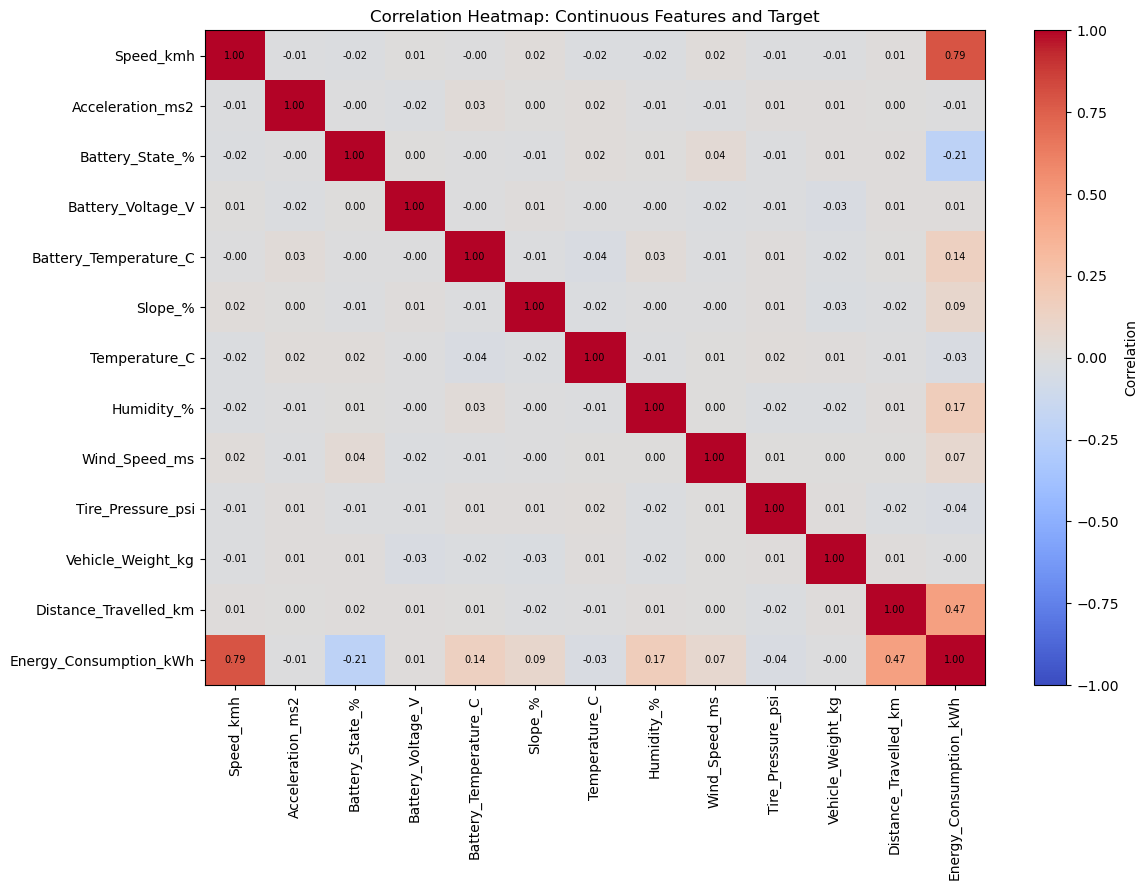

In [33]:
# Calculate correlations only for continuous numeric measurements and the target.
# Category codes are excluded because their numeric codes do not necessarily represent magnitude.
continuous_columns = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Tire_Pressure_psi",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
    target,
]

correlation_matrix = df[continuous_columns].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
image = plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for row in range(len(correlation_matrix.index)):
    for col in range(len(correlation_matrix.columns)):
        plt.text(col, row, f"{correlation_matrix.iloc[row, col]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Correlation Heatmap: Continuous Features and Target")
plt.tight_layout()
plt.show()

# Correlation describes linear association, not causation.
# A weak linear correlation does not rule out a non-linear relationship.

## 3. Define the prediction task and split the data

`Vehicle_ID` is an identifier and `Timestamp` is excluded from this first-pass model. The remaining coded fields (`Driving_Mode`, `Road_Type`, `Traffic_Condition`, and `Weather_Condition`) are categorical. We use a shuffled 80/20 split for a reproducible baseline. If the goal is to predict future trips, a chronological split should be used instead because nearby timestamps may be correlated.

In [21]:
drop_columns = [column for column in ["Vehicle_ID", "Timestamp", target] if column in df.columns]
X = df.drop(columns=drop_columns).copy()
y = df[target].copy()

categorical_columns = [
    "Driving_Mode",
    "Road_Type",
    "Traffic_Condition",
    "Weather_Condition",
]

continuous_columns = [
    "Speed_kmh",
    "Acceleration_ms2",
    "Battery_State_%",
    "Battery_Voltage_V",
    "Battery_Temperature_C",
    "Slope_%",
    "Temperature_C",
    "Humidity_%",
    "Wind_Speed_ms",
    "Tire_Pressure_psi",
    "Vehicle_Weight_kg",
    "Distance_Travelled_km",
    target,
]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric features ({len(numeric_columns)}): {numeric_columns}")
print(f"Categorical features ({len(categorical_columns)}): {categorical_columns}")


Training rows: 4,000; test rows: 1,000
Numeric features (12): ['Speed_kmh', 'Acceleration_ms2', 'Battery_State_%', 'Battery_Voltage_V', 'Battery_Temperature_C', 'Slope_%', 'Temperature_C', 'Humidity_%', 'Wind_Speed_ms', 'Tire_Pressure_psi', 'Vehicle_Weight_kg', 'Distance_Travelled_km']
Categorical features (4): ['Driving_Mode', 'Road_Type', 'Traffic_Condition', 'Weather_Condition']


## 4. Preprocessing

Missing numeric values are replaced by the training median and scaled. Categorical values are imputed with the most frequent training value and one-hot encoded. `handle_unknown='ignore'` allows categories seen only in the test set without breaking prediction. This pipeline prevents the test set from influencing preprocessing.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_columns),
    ("categorical", categorical_transformer, categorical_columns),
])


## 5. Regression models

We compare a mean-only baseline, multiple linear regression, a shallow decision tree, and K-nearest neighbors regression. The baseline helps determine whether the models improve on simply predicting the average training consumption. All scores below are calculated on the same held-out test rows.

In [ ]:
regressors = {
    "Mean baseline": None,
    "Linear regression": LinearRegression(),
    "Decision tree (depth 5)": DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
    "KNN regression (k=10)": KNeighborsRegressor(n_neighbors=10),
}

fitted_models = {}
predictions = {}
results = []
for name, estimator in regressors.items():
    if estimator is None:
        y_pred = np.full(len(y_test), y_train.mean())
    else:
        pipeline = Pipeline(steps=[("preprocess", preprocessor), ("model", estimator)])
        pipeline.fit(X_train, y_train)
        fitted_models[name] = pipeline
        y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "MAE (kWh)": mean_absolute_error(y_test, y_pred),
        "RMSE (kWh)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("RMSE (kWh)").reset_index(drop=True)
display(results_df.style.format({"MAE (kWh)": "{:.3f}", "RMSE (kWh)": "{:.3f}", "R²": "{:.3f}"}))

,Model,MAE (kWh),RMSE (kWh),R²
0,Linear regression,0.406,0.510,0.944
1,Decision tree (depth 5),0.778,0.965,0.798
2,KNN regression (k=10),0.801,0.999,0.784
3,Mean baseline,1.759,2.150,-0.001


### How to read the regression results

- **MAE** is the average absolute prediction error, in kWh. For example, an MAE of 1.2 means predictions differ from observed consumption by 1.2 kWh on average.
- **RMSE** is also in kWh and penalizes large errors more strongly than MAE.
- **R²** measures how much test-set variation is explained relative to predicting the test mean. A score near 1 is strong; 0 is similar to a mean baseline; a negative score is worse than that baseline.

Use the table's actual values as the findings. The model with the lowest test RMSE has the smallest squared-error-based test loss; also compare MAE and R² before selecting a model. A small train/test gap alone does not prove a model generalizes well, so compare its test scores with the baseline and consider validation on future data.


## 6. Cross-validation for KNN

KNN depends on the choice of `k`. We select it using five-fold cross-validation on the training set only. Each fold independently fits preprocessing, so validation folds do not leak into scaling or encoding.

Best k by mean 5-fold training RMSE: 14
Cross-validation RMSE: 1.003 kWh


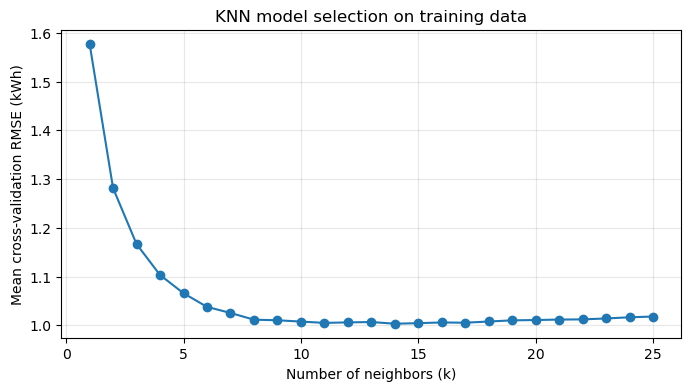

In [ ]:
k_values = range(1, 26)
knn_cv_rmse = []
for k in k_values:
    candidate = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", KNeighborsRegressor(n_neighbors=k)),
    ])
    fold_scores = cross_val_score(candidate, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    knn_cv_rmse.append(-fold_scores.mean())

best_k = list(k_values)[int(np.argmin(knn_cv_rmse))]
print(f"Best k by mean 5-fold training RMSE: {best_k}")
print(f"Cross-validation RMSE: {min(knn_cv_rmse):.3f} kWh")
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), knn_cv_rmse, marker="o")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Mean cross-validation RMSE (kWh)")
plt.title("KNN model selection on training data")
plt.grid(True, alpha=0.3)
plt.show()


The selected `k` is the value with the lowest average cross-validation RMSE. This is a model-selection estimate, not the final test score; the held-out test set remains reserved for the final comparison.

In [ ]:
best_knn = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", KNeighborsRegressor(n_neighbors=best_k)),
])
best_knn.fit(X_train, y_train)
best_knn_test_pred = best_knn.predict(X_test)
print(f"Tuned KNN test MAE: {mean_absolute_error(y_test, best_knn_test_pred):.3f} kWh")
print(f"Tuned KNN test RMSE: {np.sqrt(mean_squared_error(y_test, best_knn_test_pred)):.3f} kWh")
print(f"Tuned KNN test R²: {r2_score(y_test, best_knn_test_pred):.3f}")


Tuned KNN test MAE: 0.778 kWh
Tuned KNN test RMSE: 0.986 kWh
Tuned KNN test R²: 0.789


## 7. Interpreting a linear regression

The following coefficients are expressed per one standard deviation of a numeric feature, since numeric columns are standardized in the pipeline. A positive coefficient indicates a higher predicted energy value as that feature increases, holding the other encoded features fixed. These are associations in this dataset and do not by themselves establish causation.

In [ ]:
linear_model = fitted_models["Linear regression"]
feature_names = linear_model.named_steps["preprocess"].get_feature_names_out()
coefficients = linear_model.named_steps["model"].coef_
coefficient_table = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
coefficient_table["Absolute coefficient"] = coefficient_table["Coefficient"].abs()
display(coefficient_table.sort_values("Absolute coefficient", ascending=False).drop(columns="Absolute coefficient").head(15))
print(f"Intercept (after preprocessing): {linear_model.named_steps['model'].intercept_:.3f} kWh")


,Feature,Coefficient
0,numeric__Speed_kmh,1.723066
11,numeric__Distance_Travelled_km,0.995794
2,numeric__Battery_State_%,-0.455117
7,numeric__Humidity_%,0.397320
4,numeric__Battery_Temperature_C,0.292916
5,numeric__Slope_%,0.183430
8,numeric__Wind_Speed_ms,0.147087
12,categorical__Driving_Mode_1,-0.090033
15,categorical__Road_Type_1,-0.076053
14,categorical__Driving_Mode_3,0.074356


Intercept (after preprocessing): 8.421 kWh


The coefficient table ranks the largest model effects on its transformed inputs. Numeric features were standardized, while categorical levels became indicator columns. The intercept represents the model output when transformed features are zero; it should not be interpreted as a physical baseline trip unless that input state is meaningful.

## 8. Actual versus predicted values

Points close to the dashed diagonal are predictions close to the observed consumption. Systematic curvature or widening spread can indicate that the model misses nonlinear patterns or has errors that vary with consumption.

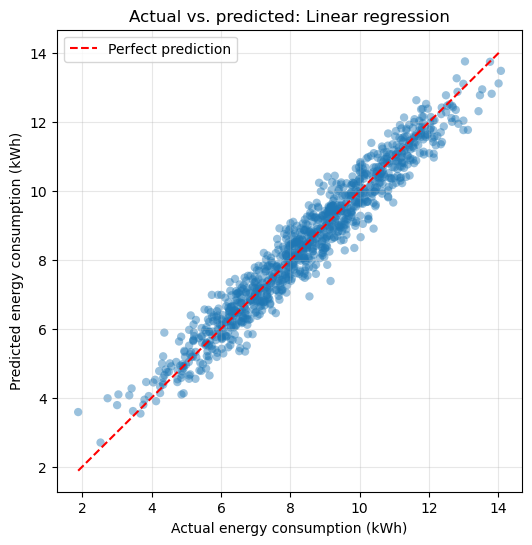

Best model by test RMSE: Linear regression


In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.45, edgecolors="none")
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
plt.xlabel("Actual energy consumption (kWh)")
plt.ylabel("Predicted energy consumption (kWh)")
plt.title(f"Actual vs. predicted: {best_model_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
print(f"Best model by test RMSE: {best_model_name}")


## 9. Optional binary classification: high versus low consumption

Logistic regression is a classifier, so the continuous kWh target must first be converted to two classes. Here, `1` means consumption is above the **training-set median** and `0` means it is at or below it. Using only the training median avoids using test target values to define the threshold. This changes the question from estimating kWh to classifying relative consumption.

In [ ]:
threshold = y_train.median()
y_train_high = (y_train > threshold).astype(int)
y_test_high = (y_test > threshold).astype(int)

classifier = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
classifier.fit(X_train, y_train_high)
class_predictions = classifier.predict(X_test)

print(f"Training median threshold: {threshold:.3f} kWh")
print(f"Accuracy:  {accuracy_score(y_test_high, class_predictions):.3f}")
print(f"Precision: {precision_score(y_test_high, class_predictions, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test_high, class_predictions, zero_division=0):.3f}")
print(f"F1 score:  {f1_score(y_test_high, class_predictions, zero_division=0):.3f}")


Training median threshold: 8.444 kWh
Accuracy:  0.924
Precision: 0.919
Recall:    0.934
F1 score:  0.926


**Classification metrics:** accuracy is the fraction of all classes predicted correctly; precision is the fraction of predicted high-consumption trips that truly are high; recall is the fraction of truly high-consumption trips detected; and F1 balances precision and recall. For imbalanced classes, accuracy alone can be misleading, so read precision, recall, and the confusion matrix together.

### Confusion matrix: how to read the counts

The positive class is **Above median** (`1`); the negative class is **At/below median** (`0`). In the matrix below, rows show the actual class and columns show the predicted class:

| Actual class | Predicted at/below median | Predicted above median |
| --- | ---: | ---: |
| At/below median | **TN** | **FP** |
| Above median | **FN** | **TP** |

- **TP (true positive):** actual consumption is above the median, and the model predicts above median.
- **TN (true negative):** actual consumption is at or below the median, and the model predicts at or below median.
- **FP (false positive):** actual consumption is at or below the median, but the model predicts above median (false alarm).
- **FN (false negative):** actual consumption is above the median, but the model predicts at or below median (missed high-consumption trip).

The code prints the count for each case from the current test predictions. The plot uses the same orientation and labels, so each cell can be matched directly to this table.

Positive class: Above median energy consumption (class 1)
TN (actual at/below, predicted at/below): 446
FP (actual at/below, predicted above):    42
FN (actual above, predicted at/below):    34
TP (actual above, predicted above):       479


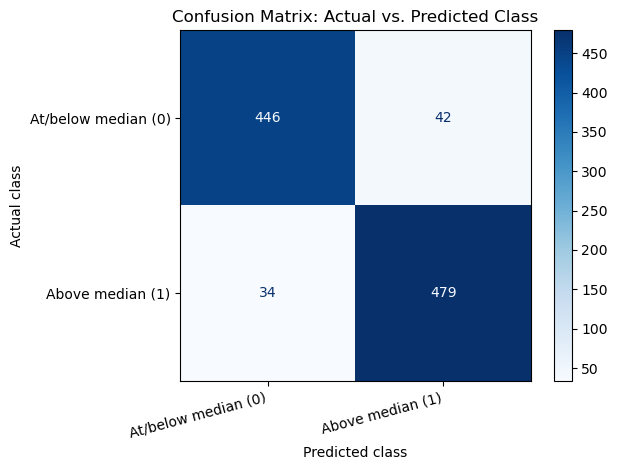

In [19]:
# Fix the class order so the matrix always has rows/columns for 0 then 1.
# Rows are actual labels; columns are predictions:
# [[TN, FP],
#  [FN, TP]]
cm = confusion_matrix(y_test_high, class_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Positive class: Above median energy consumption (class 1)")
print(f"TN (actual at/below, predicted at/below): {tn}")
print(f"FP (actual at/below, predicted above):    {fp}")
print(f"FN (actual above, predicted at/below):    {fn}")
print(f"TP (actual above, predicted above):       {tp}")

display_labels = ["At/below median (0)", "Above median (1)"]
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Actual vs. Predicted Class")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 10. Summary and limitations

Review the measured regression table to identify the best test-set model and its error in kWh. The classification section answers a different, threshold-based question. This is a baseline analysis: it excludes timestamps and vehicle identifiers, uses a random split, and does not account for repeated measurements from the same vehicle or temporal dependence. For deployment or future-trip forecasting, evaluate with a time-ordered split and, where appropriate, group by vehicle so the test data better reflects the intended use.